# Previsão de acidentes nas rodovias federais de SC (PRF 2025)

**Objetivo:** estimar a probabilidade de ocorrer pelo menos um acidente em cada **trecho de rodovia** (BR + faixa de 10 km) em um **dia**.

**Fluxo do notebook**
1. Carregar o CSV da PRF e filtrar Santa Catarina
2. Deduplicar (o arquivo tem uma linha por *pessoa* envolvida → passamos para uma linha por *acidente*)
3. Análise exploratória rápida
4. Montar a base de modelagem: trecho × dia (com zeros nos dias sem acidente)
5. Criar features (calendário + histórico do trecho, sem vazamento de informação)
6. Treinar baseline (Regressão Logística) e modelo de árvores (HistGradientBoosting)
7. Avaliar com divisão temporal e gerar o ranking de trechos de maior risco

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve

# aviso espúrio do numpy/Accelerate no macOS durante o matmul da regressão logística
warnings.filterwarnings("ignore", category=RuntimeWarning, message=".*encountered in matmul")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

CSV_PATH = "acidentes2025_todas_causas_tipos.csv"
UF = "SC"
TAMANHO_TRECHO_KM = 10   # granularidade espacial do modelo

## 1. Carga e filtro de SC

In [2]:
raw = pd.read_csv(CSV_PATH, sep=";", encoding="latin1", decimal=",", low_memory=False)
print("Brasil:", raw.shape)

sc_pessoas = raw[raw["uf"] == UF].copy()
print("SC (linhas por pessoa):", sc_pessoas.shape)

Brasil: (584010, 37)
SC (linhas por pessoa): (51403, 37)


## 2. Uma linha por acidente

O CSV "todas causas e tipos" repete o acidente para cada pessoa/veículo/causa. Para prever **ocorrência** precisamos de uma linha por `id`.
As vítimas são somadas por pessoa para não perder a gravidade.

In [3]:
vitimas = (sc_pessoas.drop_duplicates(["id", "pesid"])
           .groupby("id")[["ilesos", "feridos_leves", "feridos_graves", "mortos"]].sum())

colunas_acidente = ["id", "data_inversa", "dia_semana", "horario", "br", "km", "municipio",
                    "tipo_acidente", "classificacao_acidente", "fase_dia", "condicao_metereologica",
                    "tipo_pista", "tracado_via", "uso_solo", "latitude", "longitude", "delegacia"]

# ordem_tipo_acidente == 1 é o tipo principal; causa_principal == "Sim" é a causa principal
acidentes = (sc_pessoas.sort_values(["id", "ordem_tipo_acidente"])
             .drop_duplicates("id")[colunas_acidente]
             .merge(vitimas, on="id"))

acidentes["data"] = pd.to_datetime(acidentes["data_inversa"])
acidentes = acidentes.dropna(subset=["br", "km"])
acidentes["br"] = acidentes["br"].astype(int)
acidentes["trecho_km"] = (acidentes["km"] // TAMANHO_TRECHO_KM * TAMANHO_TRECHO_KM).astype(int)
acidentes["trecho"] = "BR-" + acidentes["br"].astype(str) + " km " + acidentes["trecho_km"].astype(str)

print(acidentes.shape, "| período:", acidentes["data"].min().date(), "→", acidentes["data"].max().date())
acidentes.head()

(8176, 24) | período: 2025-01-01 → 2025-12-31


,id,data_inversa,dia_semana,horario,br,km,municipio,tipo_acidente,classificacao_acidente,fase_dia,condicao_metereologica,tipo_pista,tracado_via,uso_solo,latitude,longitude,delegacia,ilesos,feridos_leves,feridos_graves,mortos,data,trecho_km,trecho
0,652469,2025-01-01,quarta-feira,00:50:00,101,120.0,ITAJAI,Tombamento,Com Vítimas Feridas,Plena Noite,Nublado,Dupla,Reta,Não,-26.912758,-48.711998,DEL04-SC,1.0,1.0,0.0,0.0,2025-01-01,120,BR-101 km 120
1,652478,2025-01-01,quarta-feira,03:15:00,101,143.0,ITAPEMA,Incêndio,Sem Vítimas,Plena Noite,Céu Claro,Dupla,Reta,Não,-27.064360,-48.595994,DEL04-SC,1.0,0.0,0.0,0.0,2025-01-01,140,BR-101 km 140
2,652484,2025-01-01,quarta-feira,03:15:00,101,446.0,SANTA ROSA DO SUL,Colisão traseira,Com Vítimas Feridas,Plena Noite,Céu Claro,Dupla,Reta,Não,-29.151908,-49.727093,DEL02-SC,1.0,1.0,1.0,0.0,2025-01-01,440,BR-101 km 440
3,652501,2025-01-01,quarta-feira,02:09:00,280,79.7,CORUPA,Tombamento,Com Vítimas Feridas,Plena Noite,Céu Claro,Simples,Reta,Não,-26.446573,-49.201578,DEL06-SC,0.0,1.0,0.0,0.0,2025-01-01,70,BR-280 km 70
4,652502,2025-01-01,quarta-feira,05:50:00,101,46.1,JOINVILLE,Colisão traseira,Com Vítimas Feridas,Amanhecer,Céu Claro,Dupla,Reta,Sim,-26.331501,-48.861878,DEL03-SC,1.0,1.0,0.0,0.0,2025-01-01,40,BR-101 km 40


## 3. Análise exploratória

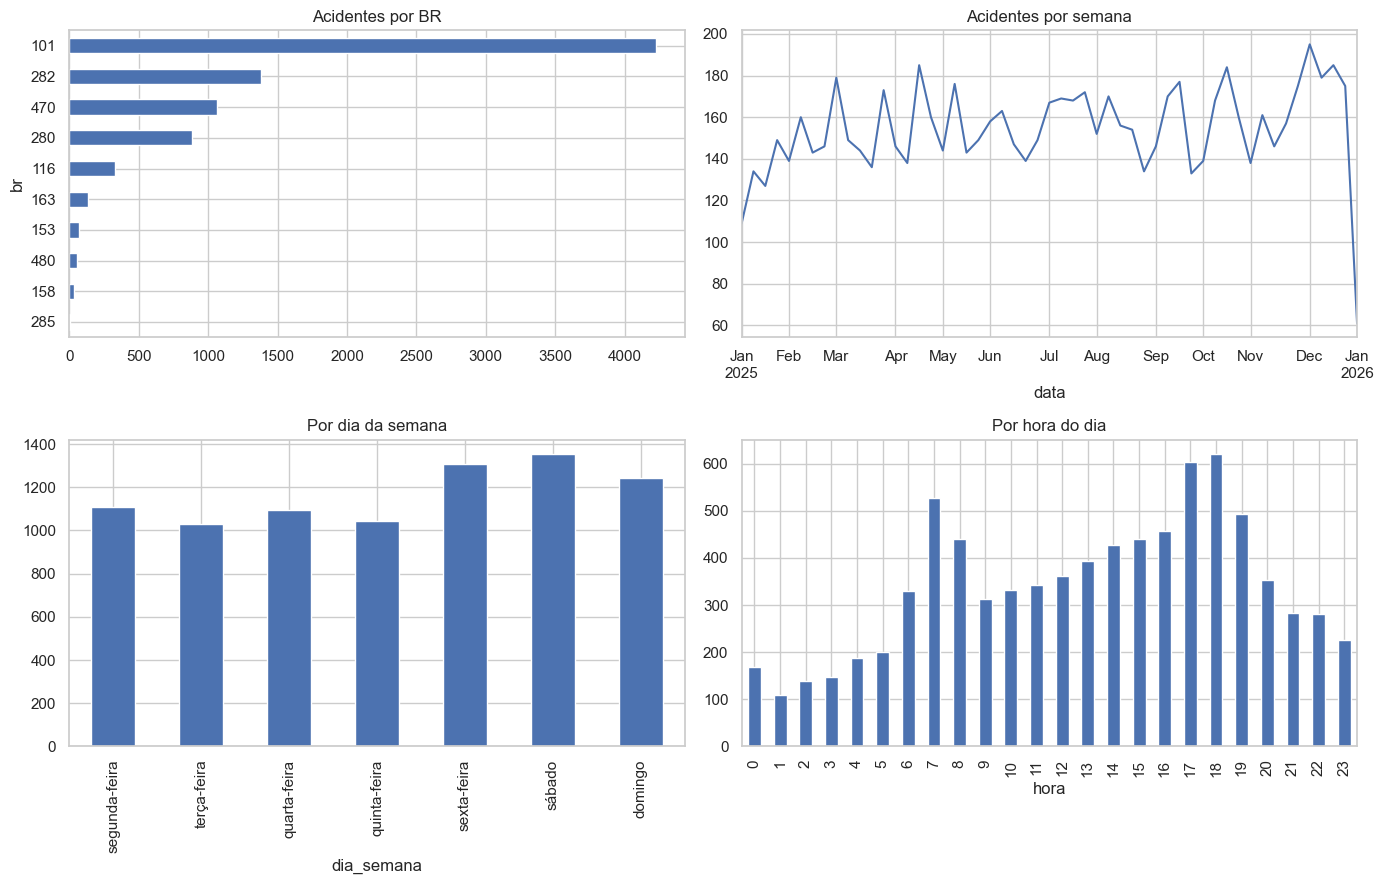

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

acidentes["br"].value_counts().head(10).plot.barh(ax=axes[0, 0], title="Acidentes por BR")
axes[0, 0].invert_yaxis()

acidentes.set_index("data").resample("W").size().plot(ax=axes[0, 1], title="Acidentes por semana")

ordem_dias = ["segunda-feira", "terça-feira", "quarta-feira", "quinta-feira", "sexta-feira", "sábado", "domingo"]
acidentes["dia_semana"].str.lower().value_counts().reindex(ordem_dias).plot.bar(ax=axes[1, 0], title="Por dia da semana")

acidentes["hora"] = pd.to_datetime(acidentes["horario"], format="%H:%M:%S").dt.hour
acidentes["hora"].value_counts().sort_index().plot.bar(ax=axes[1, 1], title="Por hora do dia")
plt.tight_layout()

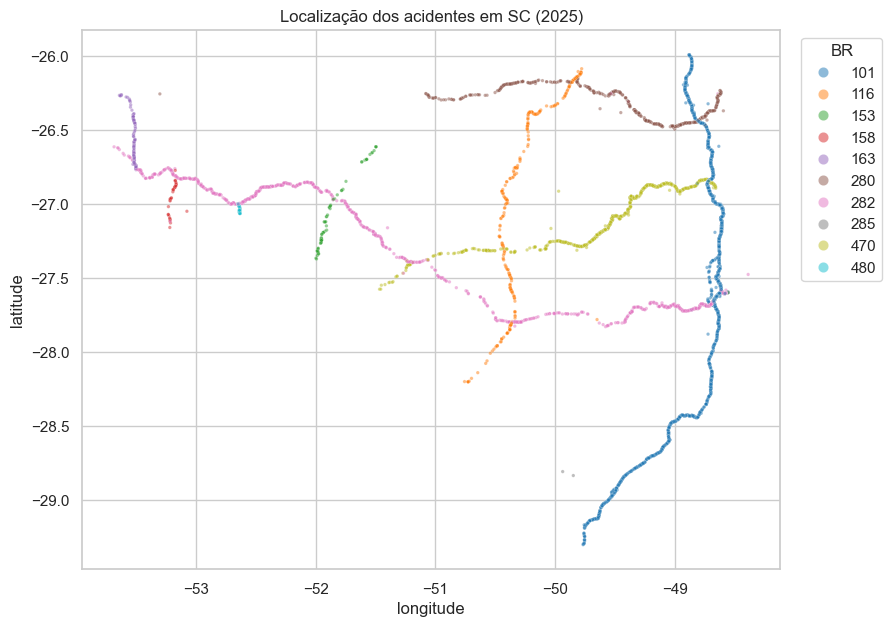

In [5]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(data=acidentes, x="longitude", y="latitude", hue="br", palette="tab10",
                s=6, alpha=.5, legend="brief", ax=ax)
ax.set_title("Localização dos acidentes em SC (2025)")
ax.legend(markerscale=3, bbox_to_anchor=(1.02, 1), loc="upper left", title="BR");

In [6]:
top_trechos = (acidentes.groupby("trecho")
               .agg(acidentes=("id", "size"), mortos=("mortos", "sum"), feridos_graves=("feridos_graves", "sum"),
                    municipio=("municipio", lambda s: s.mode().iat[0]))
               .sort_values("acidentes", ascending=False))
print("Trechos distintos com acidente:", len(top_trechos))
top_trechos.head(15)

Trechos distintos com acidente: 240


,acidentes,mortos,feridos_graves,municipio
trecho,,,,
BR-101 km 200,575,10.0,130.0,SAO JOSE
BR-101 km 210,341,4.0,108.0,PALHOCA
BR-101 km 130,279,8.0,71.0,BALNEARIO CAMBORIU
BR-101 km 190,261,8.0,60.0,BIGUACU
BR-282 km 0,260,5.0,53.0,FLORIANOPOLIS
BR-101 km 110,241,7.0,50.0,ITAJAI
BR-101 km 120,217,8.0,51.0,ITAJAI
BR-101 km 140,202,8.0,49.0,ITAPEMA
BR-280 km 20,176,3.0,52.0,ARAQUARI


## 4. Base de modelagem: trecho × dia

Cada linha = um trecho em um dia. Alvo `teve_acidente` = 1 se houve ao menos um acidente.

**Atenção a vazamento:** colunas como clima, fase do dia, tipo de pista etc. só existem *quando já houve acidente*, então **não podem ser features**. Usamos apenas o que se conhece antes do dia: calendário, localização e histórico do trecho.

> Limitação: o universo de trechos é o conjunto que teve pelo menos um acidente em 2025. Trechos sem nenhum acidente não aparecem no CSV.

In [7]:
trechos = (acidentes.groupby("trecho")
           .agg(br=("br", "first"), trecho_km=("trecho_km", "first"),
                lat=("latitude", "median"), lon=("longitude", "median"),
                delegacia=("delegacia", lambda s: s.mode().iat[0]))
           .reset_index())

datas = pd.date_range(acidentes["data"].min(), acidentes["data"].max(), freq="D")
grade = (pd.MultiIndex.from_product([trechos["trecho"], datas], names=["trecho", "data"])
         .to_frame(index=False)
         .merge(trechos, on="trecho"))

contagem = acidentes.groupby(["trecho", "data"]).size().rename("n_acidentes")
base = grade.merge(contagem, on=["trecho", "data"], how="left").fillna({"n_acidentes": 0})
base["teve_acidente"] = (base["n_acidentes"] > 0).astype(int)

print(base.shape, "| taxa de dias com acidente:", round(base["teve_acidente"].mean(), 4))

(87600, 9) | taxa de dias com acidente: 0.0781


## 5. Features

In [8]:
# Feriados nacionais 2025 (+ Carnaval). Ajuste/adicione feriados estaduais/municipais se quiser.
FERIADOS = pd.to_datetime([
    "2025-01-01", "2025-03-03", "2025-03-04", "2025-04-18", "2025-04-21", "2025-05-01",
    "2025-06-19", "2025-09-07", "2025-10-12", "2025-11-02", "2025-11-15", "2025-11-20", "2025-12-25",
])

base = base.sort_values(["trecho", "data"]).reset_index(drop=True)
base["dia_semana"] = base["data"].dt.dayofweek
base["mes"] = base["data"].dt.month
base["fim_de_semana"] = (base["dia_semana"] >= 5).astype(int)
base["feriado"] = base["data"].isin(FERIADOS).astype(int)
base["vespera_ou_pos_feriado"] = (base["data"].isin(FERIADOS - pd.Timedelta(days=1))
                                  | base["data"].isin(FERIADOS + pd.Timedelta(days=1))).astype(int)
base["temporada_verao"] = base["mes"].isin([12, 1, 2]).astype(int)  # litoral catarinense

# Histórico do trecho: shift(1) garante que só usamos dias ANTERIORES
g = base.groupby("trecho")["n_acidentes"]
for janela in [7, 30, 90]:
    base[f"acid_ult_{janela}d"] = g.transform(lambda s: s.shift(1).rolling(janela, min_periods=1).sum()).fillna(0)
base["acid_acumulado"] = g.transform(lambda s: s.shift(1).cumsum()).fillna(0)
base["dias_desde_inicio"] = (base["data"] - base["data"].min()).dt.days
base["taxa_historica"] = base["acid_acumulado"] / base["dias_desde_inicio"].clip(lower=1)

# dias desde o último acidente no trecho
ultimo = base["data"].where(base["teve_acidente"] == 1).groupby(base["trecho"]).transform(lambda s: s.shift(1).ffill())
base["dias_desde_ultimo"] = (base["data"] - ultimo).dt.days.fillna(999).clip(upper=365)

FEATURES_NUM = ["trecho_km", "lat", "lon", "dia_semana", "mes", "fim_de_semana", "feriado",
                "vespera_ou_pos_feriado", "temporada_verao", "acid_ult_7d", "acid_ult_30d",
                "acid_ult_90d", "taxa_historica", "dias_desde_ultimo"]
FEATURES_CAT = ["br", "delegacia"]
FEATURES = FEATURES_NUM + FEATURES_CAT
ALVO = "teve_acidente"
base[FEATURES + [ALVO]].describe().T

,count,mean,std,min,25%,50%,75%,max
trecho_km,87600.0,212.916667,161.211940,0.000000,90.000000,180.000000,300.000000,670.000000
lat,87600.0,-27.188289,0.704824,-29.281487,-27.631191,-27.086621,-26.705813,-26.098035
lon,87600.0,-50.425938,1.455669,-53.653191,-51.337612,-50.228893,-49.210348,-48.599705
dia_semana,87600.0,2.997260,1.997954,0.000000,1.000000,3.000000,5.000000,6.000000
mes,87600.0,6.526027,3.447871,1.000000,4.000000,7.000000,10.000000,12.000000
fim_de_semana,87600.0,0.284932,0.451384,0.000000,0.000000,0.000000,1.000000,1.000000
feriado,87600.0,0.035616,0.185333,0.000000,0.000000,0.000000,0.000000,1.000000
vespera_ou_pos_feriado,87600.0,0.068493,0.252592,0.000000,0.000000,0.000000,0.000000,1.000000
temporada_verao,87600.0,0.246575,0.431020,0.000000,0.000000,0.000000,0.000000,1.000000
acid_ult_7d,87600.0,0.646164,1.416071,0.000000,0.000000,0.000000,1.000000,27.000000


## 6. Divisão temporal

Treino: jan–set · Teste: out–dez. Nunca embaralhar datas: o modelo precisa prever o **futuro**.
Nas primeiras semanas de janeiro o histórico dos trechos ainda é curto, então as features de histórico são mais fracas ali.

In [9]:
CORTE = pd.Timestamp("2025-10-01")
treino = base[base["data"] < CORTE]
teste = base[base["data"] >= CORTE]
X_tr, y_tr = treino[FEATURES], treino[ALVO]
X_te, y_te = teste[FEATURES], teste[ALVO]
print(f"treino: {len(treino):,} linhas, positivos {y_tr.mean():.3%}")
print(f"teste:  {len(teste):,} linhas, positivos {y_te.mean():.3%}")

treino: 65,520 linhas, positivos 7.720%
teste:  22,080 linhas, positivos 8.080%


## 7. Modelos

In [10]:
pre_logit = ColumnTransformer([
    ("num", StandardScaler(), FEATURES_NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), FEATURES_CAT),
])
logit = Pipeline([("pre", pre_logit), ("clf", LogisticRegression(max_iter=2000))])

pre_hgb = ColumnTransformer([
    ("num", "passthrough", FEATURES_NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FEATURES_CAT),
])
hgb = Pipeline([("pre", pre_hgb), ("clf", HistGradientBoostingClassifier(
    learning_rate=0.05, max_iter=400, max_leaf_nodes=31, min_samples_leaf=100,
    l2_regularization=1.0, early_stopping=True, validation_fraction=0.15, random_state=42))])

modelos = {"Regressão Logística": logit, "HistGradientBoosting": hgb}
probs = {}
linhas = []
for nome, m in modelos.items():
    m.fit(X_tr, y_tr)
    p = m.predict_proba(X_te)[:, 1]
    probs[nome] = p
    linhas.append({"modelo": nome,
                   "ROC-AUC": roc_auc_score(y_te, p),
                   "PR-AUC": average_precision_score(y_te, p),
                   "Brier": brier_score_loss(y_te, p)})

# Referência ingênua: probabilidade = taxa histórica do trecho
p_ingenuo = X_te["taxa_historica"].clip(0, 1)
linhas.append({"modelo": "Ingênuo (taxa histórica)", "ROC-AUC": roc_auc_score(y_te, p_ingenuo),
               "PR-AUC": average_precision_score(y_te, p_ingenuo), "Brier": brier_score_loss(y_te, p_ingenuo)})
resultados = pd.DataFrame(linhas).set_index("modelo").round(4)
print("PR-AUC de um modelo aleatório ≈", round(y_te.mean(), 4))
resultados

PR-AUC de um modelo aleatório ≈ 0.0808


,ROC-AUC,PR-AUC,Brier
modelo,,,
Regressão Logística,0.7938,0.3520,0.0626
HistGradientBoosting,0.8033,0.3587,0.0621
Ingênuo (taxa histórica),0.8057,0.3626,0.0633


**Como ler:** ROC-AUC mede se o modelo ordena bem trechos-dia arriscados vs. seguros. PR-AUC é mais honesta com classes raras (compare com a taxa base). Brier mede se as probabilidades em si estão calibradas (menor é melhor).

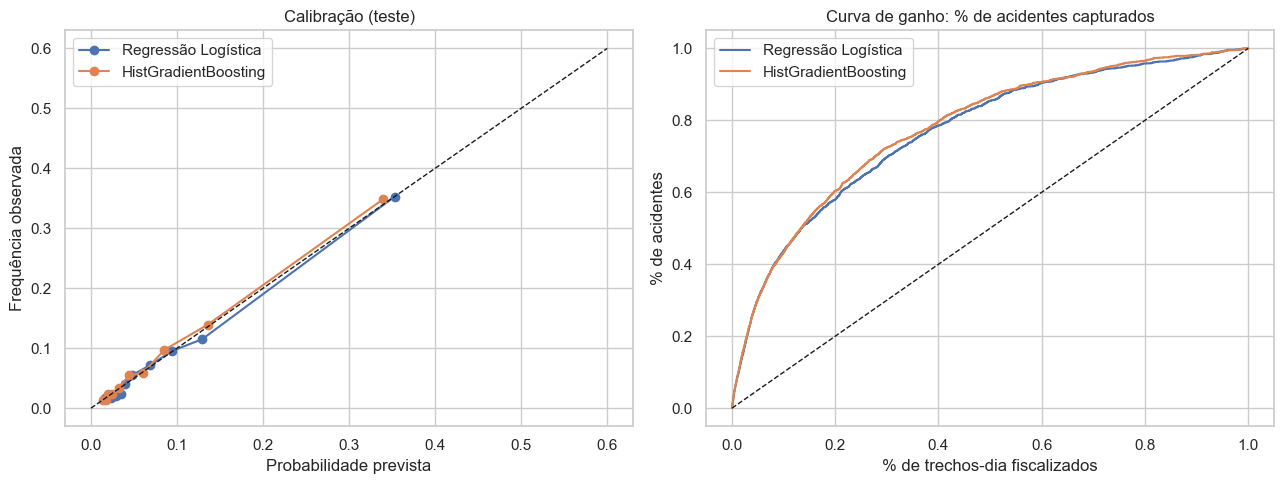

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for nome, p in probs.items():
    frac_pos, media_prev = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    ax[0].plot(media_prev, frac_pos, marker="o", label=nome)
ax[0].plot([0, .6], [0, .6], "k--", lw=1)
ax[0].set(title="Calibração (teste)", xlabel="Probabilidade prevista", ylabel="Frequência observada")
ax[0].legend()

# Capturar acidentes priorizando os trechos-dia de maior risco
for nome, p in probs.items():
    ordem = np.argsort(-p)
    captura = np.cumsum(y_te.values[ordem]) / y_te.sum()
    ax[1].plot(np.arange(1, len(p) + 1) / len(p), captura, label=nome)
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set(title="Curva de ganho: % de acidentes capturados", xlabel="% de trechos-dia fiscalizados", ylabel="% de acidentes")
ax[1].legend()
plt.tight_layout()

### Importância das features (permutação, no teste)

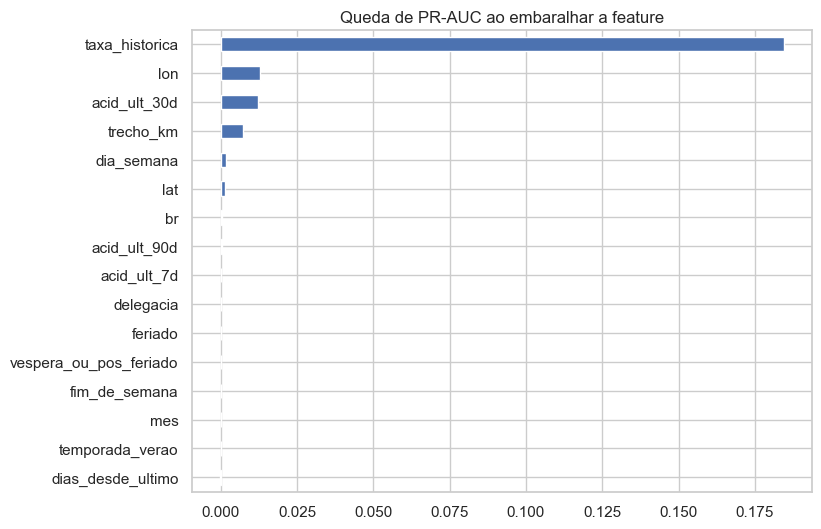

In [12]:
from sklearn.inspection import permutation_importance
amostra = teste.sample(min(30000, len(teste)), random_state=42)
imp = permutation_importance(hgb, amostra[FEATURES], amostra[ALVO], scoring="average_precision",
                             n_repeats=5, random_state=42, n_jobs=-1)
pd.Series(imp.importances_mean, index=FEATURES).sort_values().plot.barh(figsize=(8, 6), title="Queda de PR-AUC ao embaralhar a feature");

## 8. Ranking de risco por trecho

Probabilidade média diária prevista no período de teste, comparada com o que de fato aconteceu.

In [13]:
teste_res = teste[["trecho", "br", "trecho_km", "lat", "lon", "data", ALVO, "n_acidentes"]].copy()
teste_res["prob_prevista"] = probs["HistGradientBoosting"]

ranking = (teste_res.groupby(["trecho", "br", "trecho_km"])
           .agg(prob_media_dia=("prob_prevista", "mean"),
                dias_com_acidente_previstos=("prob_prevista", "sum"),
                dias_com_acidente_reais=(ALVO, "sum"),
                lat=("lat", "first"), lon=("lon", "first"))
           .sort_values("prob_media_dia", ascending=False)
           .reset_index())
ranking["prob_ao_menos_1_na_semana"] = 1 - (1 - ranking["prob_media_dia"]) ** 7
ranking.head(20).round(3)

,trecho,br,trecho_km,prob_media_dia,dias_com_acidente_previstos,dias_com_acidente_reais,lat,lon,prob_ao_menos_1_na_semana
0,BR-101 km 200,101,200,0.696,63.987,77,-27.587,-48.619,1.000
1,BR-101 km 210,101,210,0.587,53.990,53,-27.645,-48.670,0.998
2,BR-101 km 130,101,130,0.487,44.822,58,-27.004,-48.630,0.991
3,BR-282 km 0,282,0,0.487,44.819,50,-27.598,-48.600,0.991
4,BR-101 km 190,101,190,0.470,43.259,46,-27.507,-48.642,0.988
5,BR-101 km 140,101,140,0.446,41.057,37,-27.086,-48.608,0.984
6,BR-101 km 120,101,120,0.446,41.056,45,-26.947,-48.685,0.984
7,BR-101 km 110,101,110,0.435,40.042,40,-26.886,-48.720,0.982
8,BR-101 km 150,101,150,0.387,35.560,37,-27.146,-48.611,0.967
9,BR-101 km 100,101,100,0.327,30.106,30,-26.797,-48.685,0.938


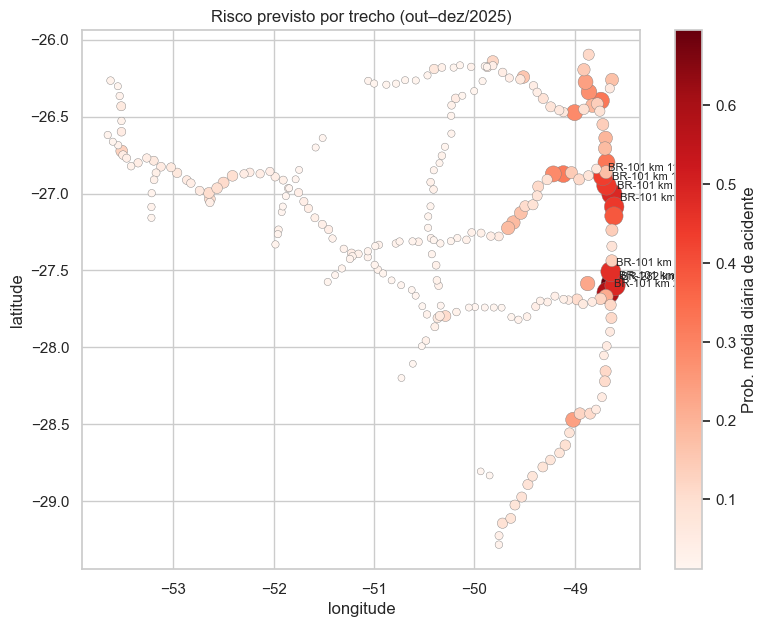

In [14]:
fig, ax = plt.subplots(figsize=(9, 7))
sc_plot = ax.scatter(ranking["lon"], ranking["lat"], c=ranking["prob_media_dia"], s=20 + 400 * ranking["prob_media_dia"],
                     cmap="Reds", edgecolor="grey", linewidth=.3)
plt.colorbar(sc_plot, label="Prob. média diária de acidente")
for _, r in ranking.head(8).iterrows():
    ax.annotate(r["trecho"], (r["lon"], r["lat"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set(title="Risco previsto por trecho (out–dez/2025)", xlabel="longitude", ylabel="latitude");

## Próximos passos sugeridos

- **Mais anos de dados** (2017–2024 no portal da PRF): mais histórico e sazonalidade real (verão, feriados), e permite incluir trechos sem acidentes em 2025.
- **Exposição / tráfego:** volume de veículos (VMDa do DNIT) por trecho é o fator que mais falta — hoje o modelo aprende "onde já aconteceu".
- **Clima previsto** (INMET/Open-Meteo) por dia e região, sem vazamento.
- **Granularidade de tempo:** trecho × período do dia (madrugada/manhã/tarde/noite).
- **Outros alvos:** acidente grave/fatal, ou contagem esperada (regressão de Poisson).
- Ajustar o tamanho do trecho (`TAMANHO_TRECHO_KM`) e testar validação temporal em janelas móveis.